# RCAN — SEMICON v2

Complete 300-epoch maximum benchmark. Approximately 25–45 T4 hours; use resume across Kaggle sessions. Early stopping may finish sooner. Enable Internet for the one-time LPIPS package/weights setup.


## Configuration, reproducibility, automatic path detection, and T4 guard


In [1]:
%pip install -q lpips
from __future__ import annotations
import json,math,os,random,time
from collections import defaultdict
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch,torch.nn as nn,torch.nn.functional as F
from PIL import Image
from torch.utils.data import Dataset,DataLoader
from tqdm.auto import tqdm
import lpips

MODEL_NAME='RCAN'; TASK='sr'; DATASET_TOKEN='SEMICON-SR-2X-v2'
ROOT=Path("/kaggle/input"); OUT=Path("/kaggle/working")
SEED=2026; EPOCHS=300; SCALE=2 if TASK=="sr" else 1
PATCH=96 if TASK=="sr" else 256
BATCH=16; ACCUM=1; LR=2e-4
WORKERS=min(4,os.cpu_count() or 1); PATIENCE=15
TILE=160; HALO=32; AMP=True
BEST=OUT/f"best_{MODEL_NAME.lower()}.pth"; LAST=OUT/f"last_{MODEL_NAME.lower()}.pth"
HISTORY=OUT/f"{MODEL_NAME.lower()}_history.csv"
RESULTS=OUT/f"{MODEL_NAME.lower()}_results.csv"
CURVES=OUT/f"{MODEL_NAME.lower()}_curves.png"
PREDICTIONS=OUT/f"{MODEL_NAME.lower()}_predictions.png"

def seed_all(seed):
 os.environ["PYTHONHASHSEED"]=str(seed); random.seed(seed); np.random.seed(seed)
 torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
 torch.backends.cudnn.benchmark=True; torch.backends.cudnn.deterministic=False
seed_all(SEED)
if not torch.cuda.is_available(): raise RuntimeError("Enable a Kaggle T4 GPU.")
arch="sm_%d%d"%torch.cuda.get_device_capability(0)
if arch not in torch.cuda.get_arch_list(): raise RuntimeError(f"{arch} unsupported; select T4.")
DEVICE=torch.device("cuda")

def find_manifest(token):
 candidates=list(ROOT.rglob("manifest.json"))
 scored=[]
 for p in candidates:
  path_str=p.as_posix().casefold()
  if "sr_2x" not in path_str or "noise" in path_str: continue
  try:
   data=json.loads(p.read_text())
   label=(str(data.get("dataset",""))+" "+p.as_posix()).casefold()
   scored.append((int(token.casefold() in label),p,data))
  except Exception: pass
 if not scored: raise FileNotFoundError(f"No SR_2X (non-Noise) manifest found for {token} under /kaggle/input")
 _,p,data=max(scored,key=lambda x:x[0])
 print("Using SR_2X manifest:",p)
 assert "noise" not in p.as_posix().casefold(), "Accidentally resolved to Noise dataset!"
 return p.parent,data
DATA_ROOT,payload=find_manifest(DATASET_TOKEN)
records=payload if isinstance(payload,list) else payload["samples"]
print("DATA_ROOT:",DATA_ROOT)
print("Total records:",len(records))
print(MODEL_NAME,TASK,torch.cuda.get_device_name(0),DATA_ROOT,len(records))


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.8/53.8 kB 4.2 MB/s eta 0:00:00
Note: you may need to restart the kernel to use updated packages.
Using SR_2X manifest: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2/manifest.json
DATA_ROOT: /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2
Total records: 4158
RCAN sr Tesla T4 /kaggle/input/datasets/omkadam05/semicon-v2-dual-dataset/SEMICON_SR_2X_v2/SEMICON_SR_2X_v2 4158


## Manifest-driven paired data loading and GPU-memory-conscious aligned crops


In [2]:
class Pairs(Dataset):
 def __init__(self,items,mode): self.items,self.mode=items,mode
 def __len__(self): return len(self.items)
 def read(self,p):
  with Image.open(DATA_ROOT/p) as im: a=np.asarray(im.convert("L"),np.float32).copy()/255.
  return torch.from_numpy(a)[None]
 def __getitem__(self,i):
  x=self.items[i]; lr,hr=self.read(x["lr_path"]),self.read(x["hr_path"])
  if hr.shape[-2:]!=(lr.shape[-2]*SCALE,lr.shape[-1]*SCALE): raise ValueError(x["sample_id"])
  if self.mode!="test":
   p=PATCH; h,w=lr.shape[-2:]
   top=random.randint(0,h-p) if self.mode=="train" else (h-p)//2
   left=random.randint(0,w-p) if self.mode=="train" else (w-p)//2
   lr=lr[:,top:top+p,left:left+p]
   hr=hr[:,top*SCALE:(top+p)*SCALE,left*SCALE:(left+p)*SCALE]
   if self.mode=="train":
    if random.random()<.5: lr,hr=lr.flip(-1),hr.flip(-1)
    if random.random()<.5: lr,hr=lr.flip(-2),hr.flip(-2)
    k=random.randrange(4); lr,hr=torch.rot90(lr,k,(-2,-1)),torch.rot90(hr,k,(-2,-1))
  return {"lr":lr.contiguous(),"hr":hr.contiguous(),"sample_id":x["sample_id"],
          "category":x.get("category","sr"),"degradation_type":x.get("degradation_type","")}
def init_worker(_): seed=torch.initial_seed()%2**32; random.seed(seed); np.random.seed(seed)
sets={s:[x for x in records if x["split"]==s] for s in ("train","val","test")}
train,val,test=Pairs(sets["train"],"train"),Pairs(sets["val"],"val"),Pairs(sets["test"],"test")
kw=dict(num_workers=WORKERS,pin_memory=True,persistent_workers=WORKERS>0,worker_init_fn=init_worker)
gen=torch.Generator().manual_seed(SEED)
train_loader=DataLoader(train,BATCH,shuffle=True,drop_last=True,generator=gen,**kw)
val_loader=DataLoader(val,BATCH,shuffle=False,**kw); test_loader=DataLoader(test,1,shuffle=False,**kw)
print({k:len(v) for k,v in sets.items()})


{'train': 2910, 'val': 831, 'test': 417}


## PSNR, Gaussian SSIM, genuine AlexNet LPIPS, and halo tiled inference


In [3]:
lpips_metric=lpips.LPIPS(net="alex").to(DEVICE).eval()
for p in lpips_metric.parameters(): p.requires_grad=False
def psnr(pred,target):
 mse=(pred.float().clamp(0,1)-target.float()).square().flatten(1).mean(1)
 return -10*torch.log10(mse.clamp_min(1e-12))
def window(device):
 x=torch.arange(11,device=device,dtype=torch.float32)-5
 g=torch.exp(-(x*x)/(2*1.5**2)); g/=g.sum(); return (g[:,None]*g[None,:])[None,None]
def ssim(pred,target):
 x,y=pred.float().clamp(0,1),target.float(); w=window(x.device); p=5
 x,y=F.pad(x,(p,)*4,mode="reflect"),F.pad(y,(p,)*4,mode="reflect")
 mx,my=F.conv2d(x,w),F.conv2d(y,w)
 vx,vy=F.conv2d(x*x,w)-mx.square(),F.conv2d(y*y,w)-my.square()
 vxy=F.conv2d(x*y,w)-mx*my; c1,c2=.01**2,.03**2
 return (((2*mx*my+c1)*(2*vxy+c2))/((mx.square()+my.square()+c1)*(vx+vy+c2)).clamp_min(1e-12)).flatten(1).mean(1)
def lpips_score(pred,target):
 x=pred.float().clamp(0,1).repeat(1,3,1,1)*2-1
 y=target.float().repeat(1,3,1,1)*2-1
 return lpips_metric(x,y).flatten()
def amp(): return torch.autocast("cuda",dtype=torch.float16,enabled=AMP)
@torch.inference_mode()
def tiled(model,x):
 _,c,h,w=x.shape; out=torch.empty((1,c,h*SCALE,w*SCALE),device=x.device)
 for y0 in range(0,h,TILE):
  for x0 in range(0,w,TILE):
   y1,x1=min(h,y0+TILE),min(w,x0+TILE)
   a,b=max(0,y0-HALO),max(0,x0-HALO); d,e=min(h,y1+HALO),min(w,x1+HALO)
   with amp(): tile=model(x[...,a:d,b:e]).float()
   oy,ox=(y0-a)*SCALE,(x0-b)*SCALE
   out[...,y0*SCALE:y1*SCALE,x0*SCALE:x1*SCALE]=tile[...,oy:oy+(y1-y0)*SCALE,ox:ox+(x1-x0)*SCALE]
 return out


Setting up [LPIPS] perceptual loss: trunk [alex], v[0.1], spatial [off]


/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


Downloading: "https://download.pytorch.org/models/alexnet-owt-7be5be79.pth" to /root/.cache/torch/hub/checkpoints/alexnet-owt-7be5be79.pth


100%|██████████| 233M/233M [00:01<00:00, 217MB/s]


Loading model from: /usr/local/lib/python3.12/dist-packages/lpips/weights/v0.1/alex.pth


## RCAN architecture


In [4]:
class CA(nn.Module):
 def __init__(self,c): super().__init__(); self.m=nn.Sequential(nn.AdaptiveAvgPool2d(1),nn.Conv2d(c,c//16,1),nn.ReLU(True),nn.Conv2d(c//16,c,1),nn.Sigmoid())
 def forward(self,x): return x*self.m(x)
class RCAB(nn.Module):
 def __init__(self,c): super().__init__(); self.m=nn.Sequential(nn.Conv2d(c,c,3,1,1),nn.ReLU(True),nn.Conv2d(c,c,3,1,1),CA(c))
 def forward(self,x): return x+.1*self.m(x)
class Group(nn.Module):
 def __init__(self,c): super().__init__(); self.m=nn.Sequential(*[RCAB(c) for _ in range(10)],nn.Conv2d(c,c,3,1,1))
 def forward(self,x): return x+self.m(x)
class RCAN(nn.Module):
 def __init__(self,c=64): super().__init__(); self.h=nn.Conv2d(1,c,3,1,1); self.b=nn.Sequential(*[Group(c) for _ in range(5)],nn.Conv2d(c,c,3,1,1)); self.u=nn.Sequential(nn.Conv2d(c,4*c,3,1,1),nn.PixelShuffle(2),nn.Conv2d(c,1,3,1,1))
 def forward(self,x): f=self.h(x); return self.u(f+self.b(f))
model=RCAN().to(DEVICE)


## Training: AMP, AdamW, cosine decay, clipping, best/last checkpoints, resume, early stopping


In [5]:
criterion=nn.L1Loss(); optimizer=torch.optim.AdamW(model.parameters(),lr=LR,betas=(.9,.99))
scheduler=torch.optim.lr_scheduler.CosineAnnealingLR(optimizer,EPOCHS,eta_min=1e-6)
scaler=torch.amp.GradScaler("cuda"); history=[]; start=1; best=-1e9; stale=0
resume=LAST if LAST.exists() else next(iter(ROOT.rglob(LAST.name)),None)
if resume:
 ck=torch.load(resume,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"]); optimizer.load_state_dict(ck["optimizer"]); scheduler.load_state_dict(ck["scheduler"]); scaler.load_state_dict(ck["scaler"]); history=ck["history"]; start=ck["epoch"]+1; best=ck["best"]; stale=ck["stale"]; print("Resumed",resume)
@torch.inference_mode()
def validate():
 model.eval(); ls=[]; ps=[]; ss=[]
 for b in tqdm(val_loader,desc="Validation",leave=False):
  x,y=b["lr"].to(DEVICE,non_blocking=True),b["hr"].to(DEVICE,non_blocking=True)
  with amp(): z=model(x); loss=criterion(z,y)
  ls.append(loss.item()); ps.extend(psnr(z,y).cpu().tolist()); ss.extend(ssim(z,y).cpu().tolist())
 return np.mean(ls),np.mean(ps),np.mean(ss),0.0
for epoch in range(start,EPOCHS+1):
 model.train(); optimizer.zero_grad(set_to_none=True); total=0
 bar=tqdm(train_loader,desc=f"{MODEL_NAME} {epoch}/{EPOCHS}")
 for step,b in enumerate(bar,1):
  x,y=b["lr"].to(DEVICE,non_blocking=True),b["hr"].to(DEVICE,non_blocking=True)
  with amp(): z=model(x); raw=criterion(z,y); loss=raw/ACCUM
  scaler.scale(loss).backward()
  if step%ACCUM==0 or step==len(train_loader):
   scaler.unscale_(optimizer); nn.utils.clip_grad_norm_(model.parameters(),1.0); scaler.step(optimizer); scaler.update(); optimizer.zero_grad(set_to_none=True)
  total+=raw.item(); bar.set_postfix(loss=f"{raw.item():.4f}")
 vl,vp,vs,vpips=validate(); scheduler.step()
 row=dict(epoch=epoch,train_loss=total/len(train_loader),val_loss=vl,psnr=vp,ssim=vs,lpips=vpips,lr=optimizer.param_groups[0]["lr"]); history.append(row)
 improved=vp>best; best=max(best,vp); stale=0 if improved else stale+1
 state=dict(epoch=epoch,model=model.state_dict(),optimizer=optimizer.state_dict(),scheduler=scheduler.state_dict(),scaler=scaler.state_dict(),history=history,best=best,stale=stale,config=dict(model=MODEL_NAME,task=TASK,seed=SEED))
 torch.save(state,LAST)
 if improved: torch.save(state,BEST)
 pd.DataFrame(history).to_csv(HISTORY,index=False); print(row,"BEST" if improved else "")
 if stale>=PATIENCE: print("Early stopping"); break


RCAN 1/300:   0%|          | 0/181 [00:00<?, ?it/s]

Validation:   0%|          | 0/52 [00:00<?, ?it/s]

{'epoch': 1, 'train_loss': 0.045207244256583366, 'val_loss': np.float64(0.035341356021280475), 'psnr': np.float64(27.387532925060654), 'ssim': np.float64(0.6771990237970501), 'lpips': 0.0, 'lr': 0.00019999454435186845} BEST


RCAN 2/300:   0%|          | 0/181 [00:00<?, ?it/s]

Validation:   0%|          | 0/52 [00:00<?, ?it/s]

...

Validation:   0%|          | 0/52 [00:00<?, ?it/s]

{'epoch': 173, 'train_loss': 0.028657785282362232, 'val_loss': np.float64(0.030812112757792838), 'psnr': np.float64(29.234769536556605), 'ssim': np.float64(0.7137351338039953), 'lpips': 0.0, 'lr': 7.676592097093119e-05} 


RCAN 174/300:   0%|          | 0/181 [00:00<?, ?it/s]

Validation:   0%|          | 0/52 [00:00<?, ?it/s]

{'epoch': 174, 'train_loss': 0.028960192164416473, 'val_loss': np.float64(0.030798065941780806), 'psnr': np.float64(29.234412176084003), 'ssim': np.float64(0.7135712436246815), 'lpips': 0.0, 'lr': 7.575535622709694e-05} 
Early stopping


## Curves, native-resolution test benchmark, CSV, and visual predictions


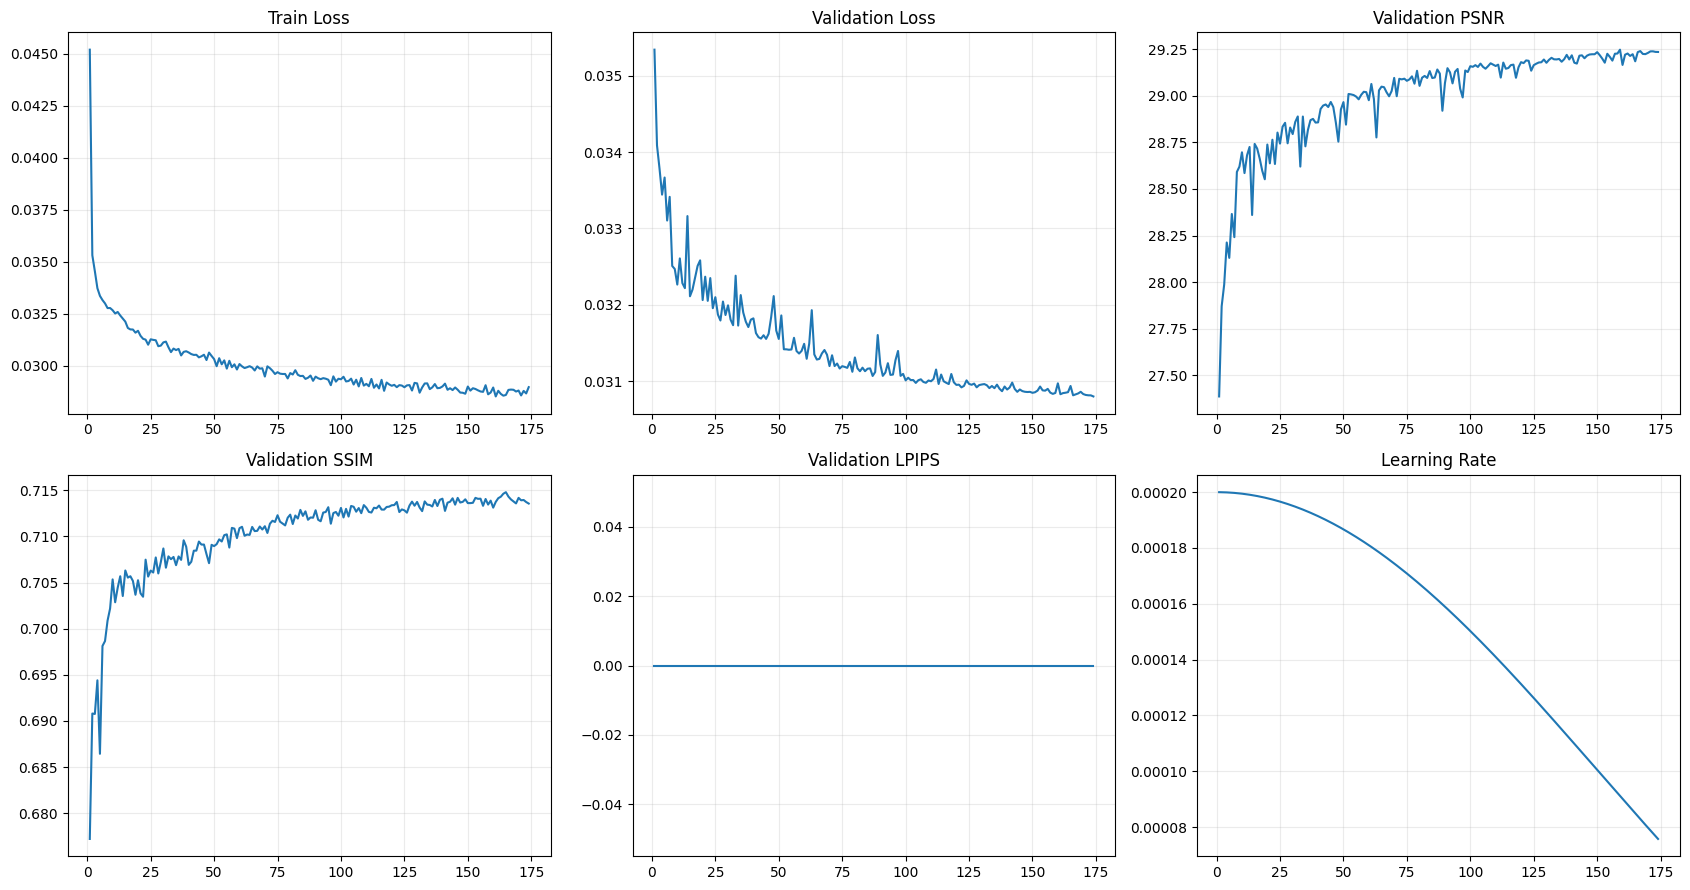

Native test:   0%|          | 0/417 [00:00<?, ?it/s]

,model,psnr,ssim,lpips,parameters,ms_per_image,best_epoch
0,RCAN,28.918161,0.719652,0.143205,4092297,472.207903,159


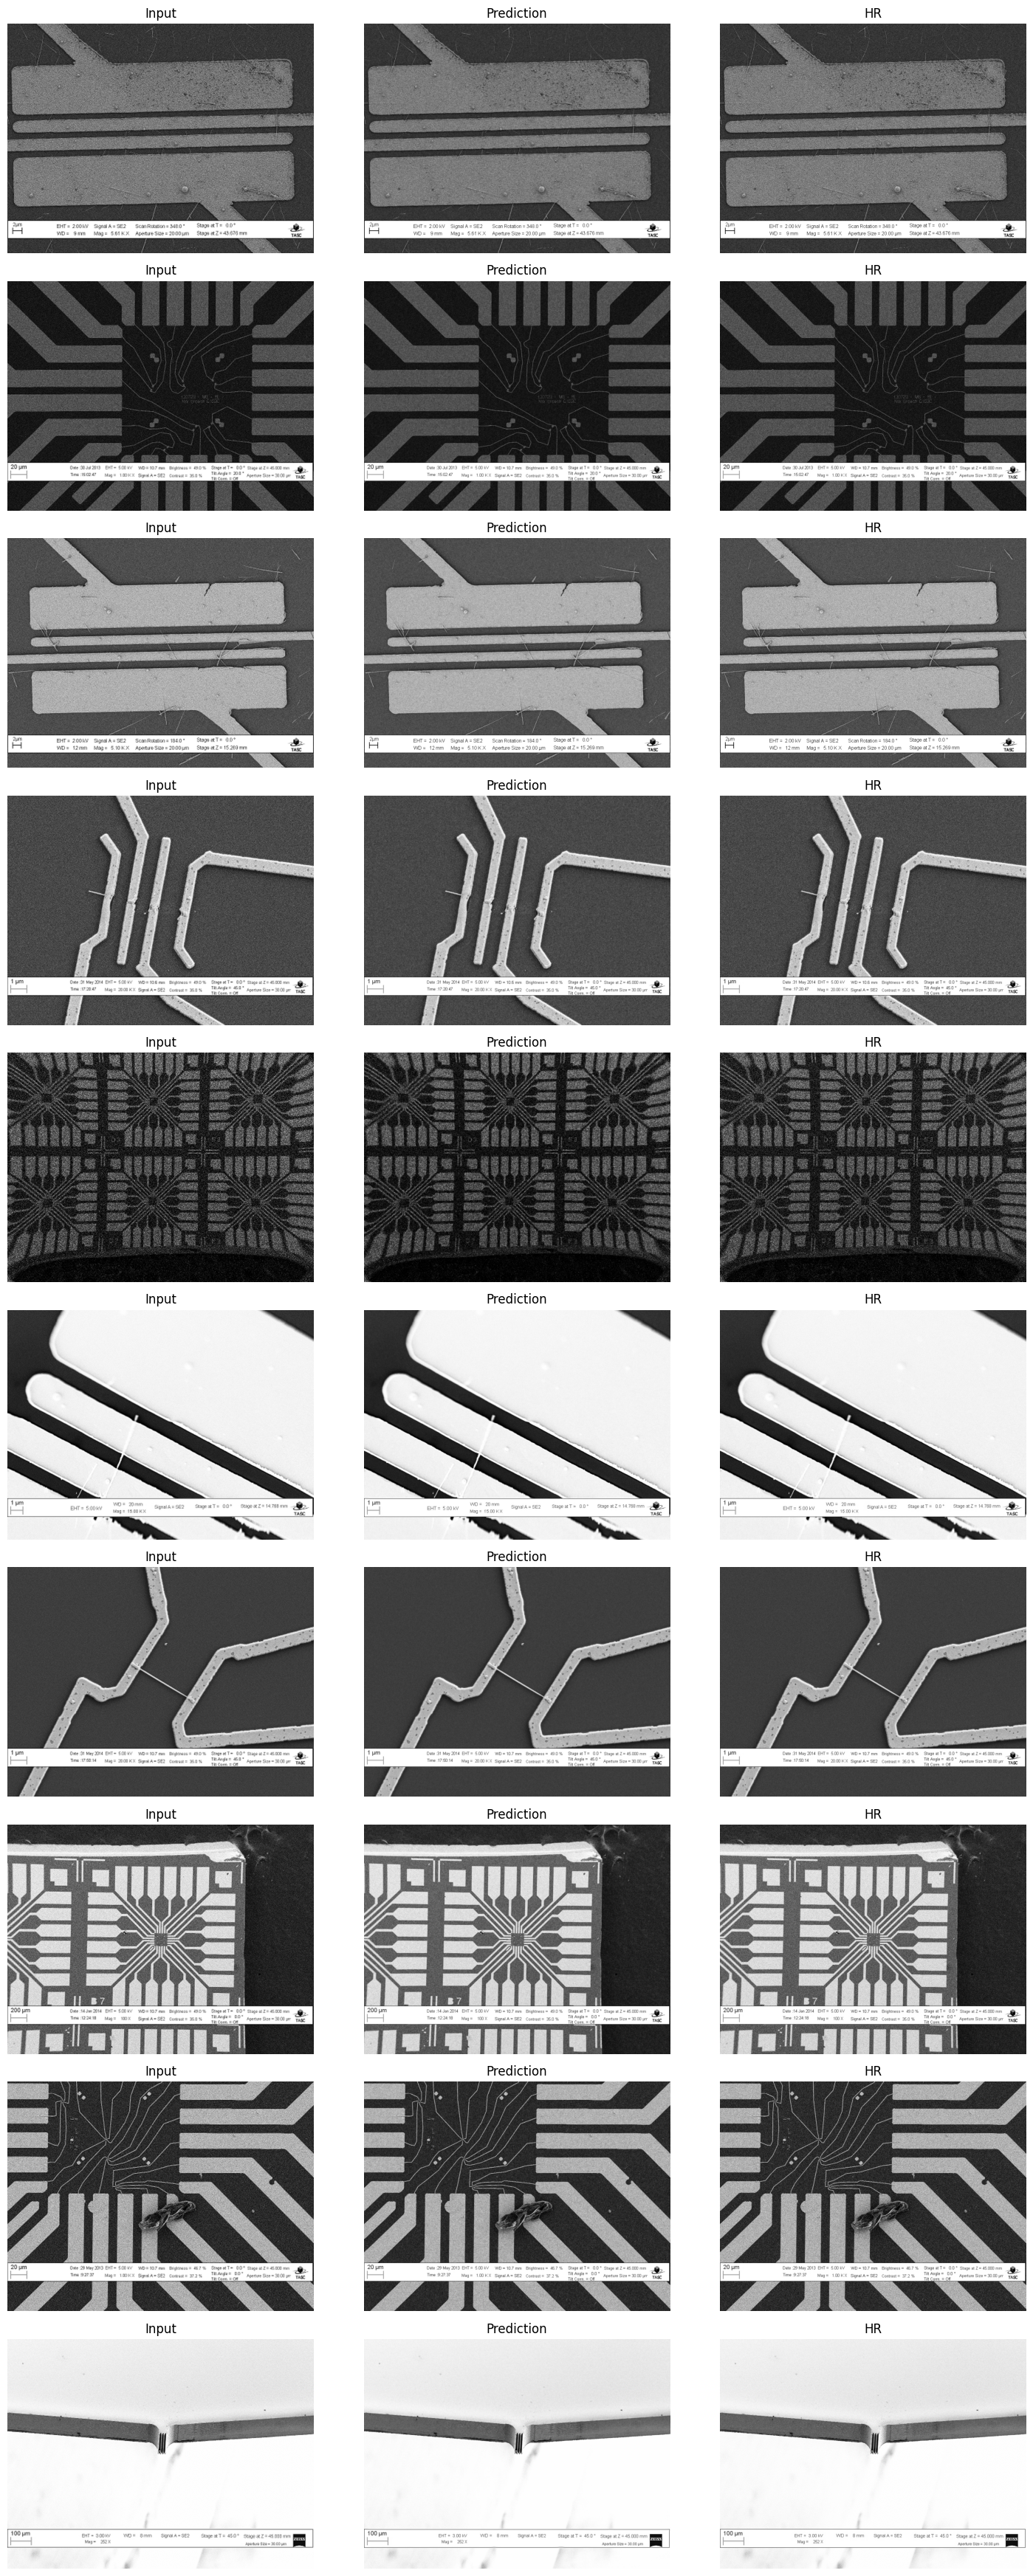

In [6]:
h=pd.DataFrame(history); fig,ax=plt.subplots(2,3,figsize=(17,9))
for a,c,t in zip(ax.flat,["train_loss","val_loss","psnr","ssim","lpips","lr"],["Train Loss","Validation Loss","Validation PSNR","Validation SSIM","Validation LPIPS","Learning Rate"]): a.plot(h.epoch,h[c]); a.set_title(t); a.grid(alpha=.25)
fig.tight_layout(); fig.savefig(CURVES,dpi=180); plt.show()
ck=torch.load(BEST,map_location=DEVICE,weights_only=False); model.load_state_dict(ck["model"]); model.eval()
rows=[]; timing=[]
with torch.inference_mode():
 for b in tqdm(test_loader,desc="Native test"):
  x,y=b["lr"].to(DEVICE),b["hr"].to(DEVICE); torch.cuda.synchronize(); t=time.perf_counter(); z=tiled(model,x).clamp(0,1); torch.cuda.synchronize(); timing.append(time.perf_counter()-t)
  rows.append((psnr(z,y).item(),ssim(z,y).item(),lpips_score(z,y).item()))
result=pd.DataFrame([dict(model=MODEL_NAME,psnr=np.mean([x[0] for x in rows]),ssim=np.mean([x[1] for x in rows]),lpips=np.mean([x[2] for x in rows]),parameters=sum(p.numel() for p in model.parameters()),ms_per_image=1000*np.mean(timing),best_epoch=ck["epoch"])])
result.to_csv(RESULTS,index=False); display(result)
idx=np.random.default_rng(SEED).choice(len(test),10,replace=False); fig,ax=plt.subplots(10,3,figsize=(15,35))
for r,i in enumerate(idx):
 s=test[int(i)]; x=s["lr"][None].to(DEVICE); z=tiled(model,x).clamp(0,1).cpu().squeeze().numpy(); y=s["hr"].squeeze().numpy(); inp=F.interpolate(x,scale_factor=SCALE,mode="bicubic",align_corners=False).cpu().squeeze().numpy() if SCALE==2 else x.cpu().squeeze().numpy()
 for a,im,t in zip(ax[r],[inp,z,y],["Input","Prediction","HR"]): a.imshow(im,cmap="gray",vmin=0,vmax=1); a.set_title(t); a.axis("off")
fig.tight_layout(); fig.savefig(PREDICTIONS,dpi=150); plt.show()


## Inference script


In [7]:
def load_inference_model(checkpoint=BEST):
 state=torch.load(checkpoint,map_location=DEVICE,weights_only=False)
 model.load_state_dict(state["model"]); model.eval(); return model
@torch.inference_mode()
def infer_png(input_path,output_path):
 with Image.open(input_path) as im: arr=np.asarray(im.convert("L"),np.float32).copy()/255.
 x=torch.from_numpy(arr)[None,None].to(DEVICE); prediction=tiled(load_inference_model(),x).clamp(0,1)
 out=np.rint(prediction.cpu().squeeze().numpy()*255).astype(np.uint8)
 Image.fromarray(out,mode="L").save(output_path)
 return Path(output_path)
# Example: infer_png("/kaggle/working/input.png","/kaggle/working/prediction.png")


## Final benchmark table

The final cell exports one row containing PSNR, SSIM, LPIPS, parameters, synchronized T4 latency, and best epoch. Concatenate these CSV files for the project benchmark table.
